# EDA with Data Visualization
Goal: use scatter, bar and line charts to see how flight number, payload, launch site, orbit and year relate to landing success, then engineer features for modelling.

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

In [2]:
if os.path.exists('dataset_part_2.csv'):
    df = pd.read_csv('dataset_part_2.csv')
else:
    df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,6/4/2010,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1,0,B0003,-80.577366,28.561857,0
1,2,5/22/2012,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1,0,B0005,-80.577366,28.561857,0
2,3,3/1/2013,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1,0,B0007,-80.577366,28.561857,0
3,4,9/29/2013,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1,0,B1003,-120.610829,34.632093,0
4,5,12/3/2013,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1,0,B1004,-80.577366,28.561857,0


## Flight Number vs Payload Mass

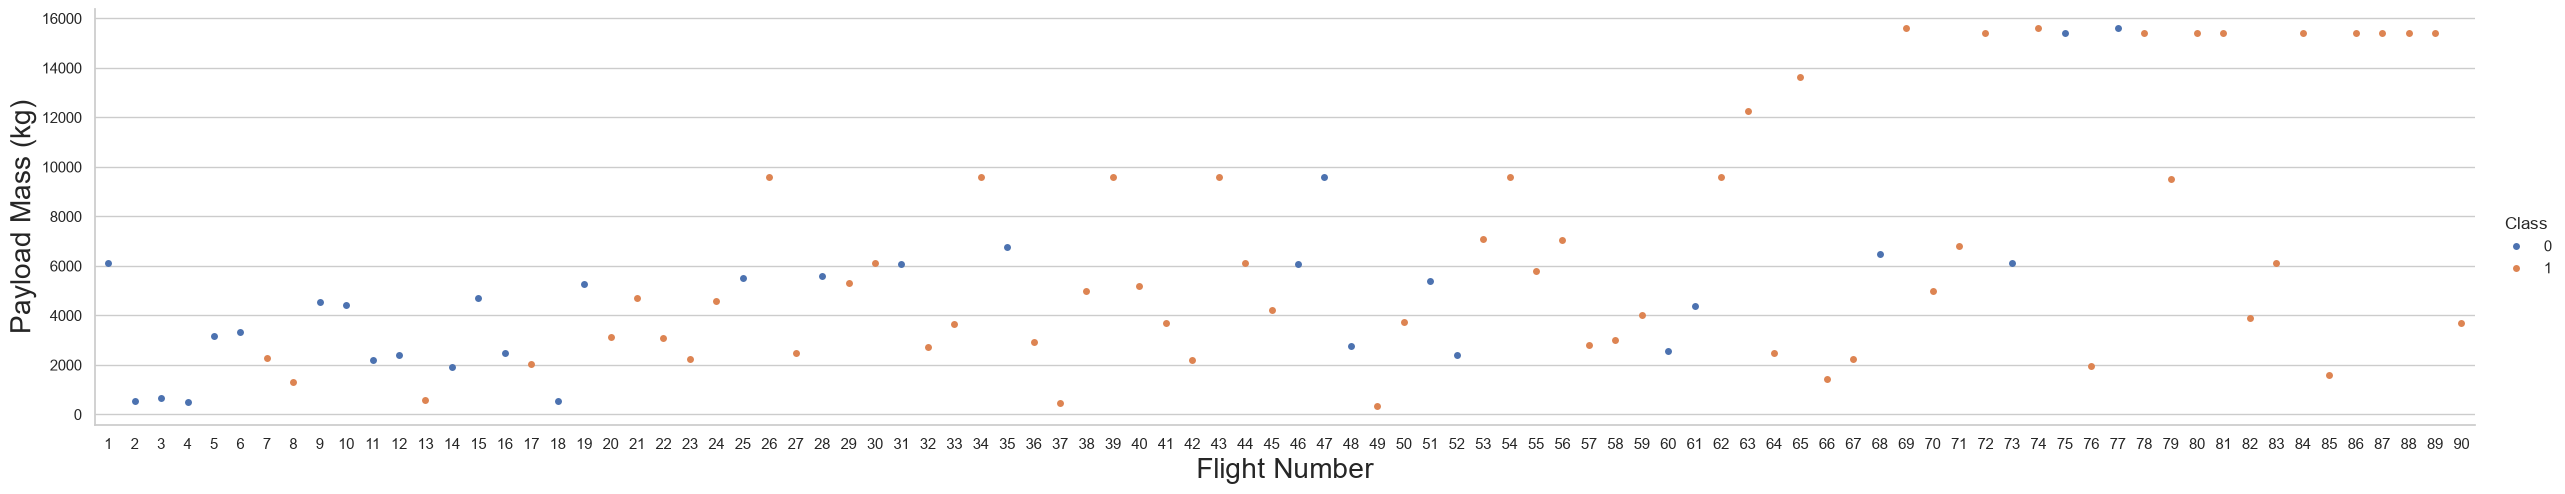

In [3]:
sns.catplot(y='PayloadMass', x='FlightNumber', hue='Class', data=df, aspect=5)
plt.xlabel('Flight Number', fontsize=20); plt.ylabel('Payload Mass (kg)', fontsize=20)
plt.show()

## Flight Number vs Launch Site

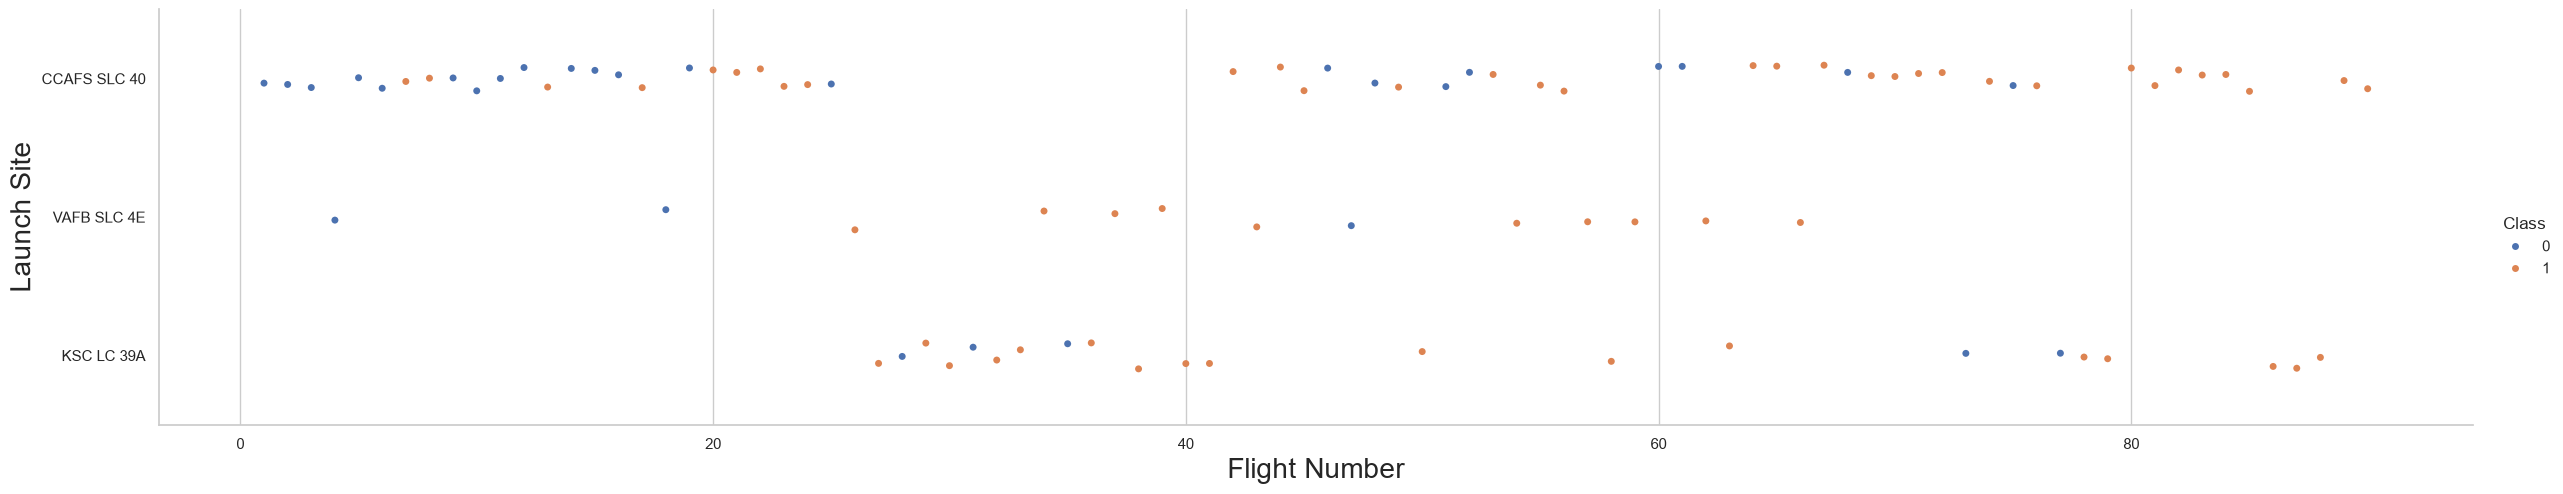

In [4]:
sns.catplot(y='LaunchSite', x='FlightNumber', hue='Class', data=df, aspect=5)
plt.xlabel('Flight Number', fontsize=20); plt.ylabel('Launch Site', fontsize=20)
plt.show()

## Payload vs Launch Site

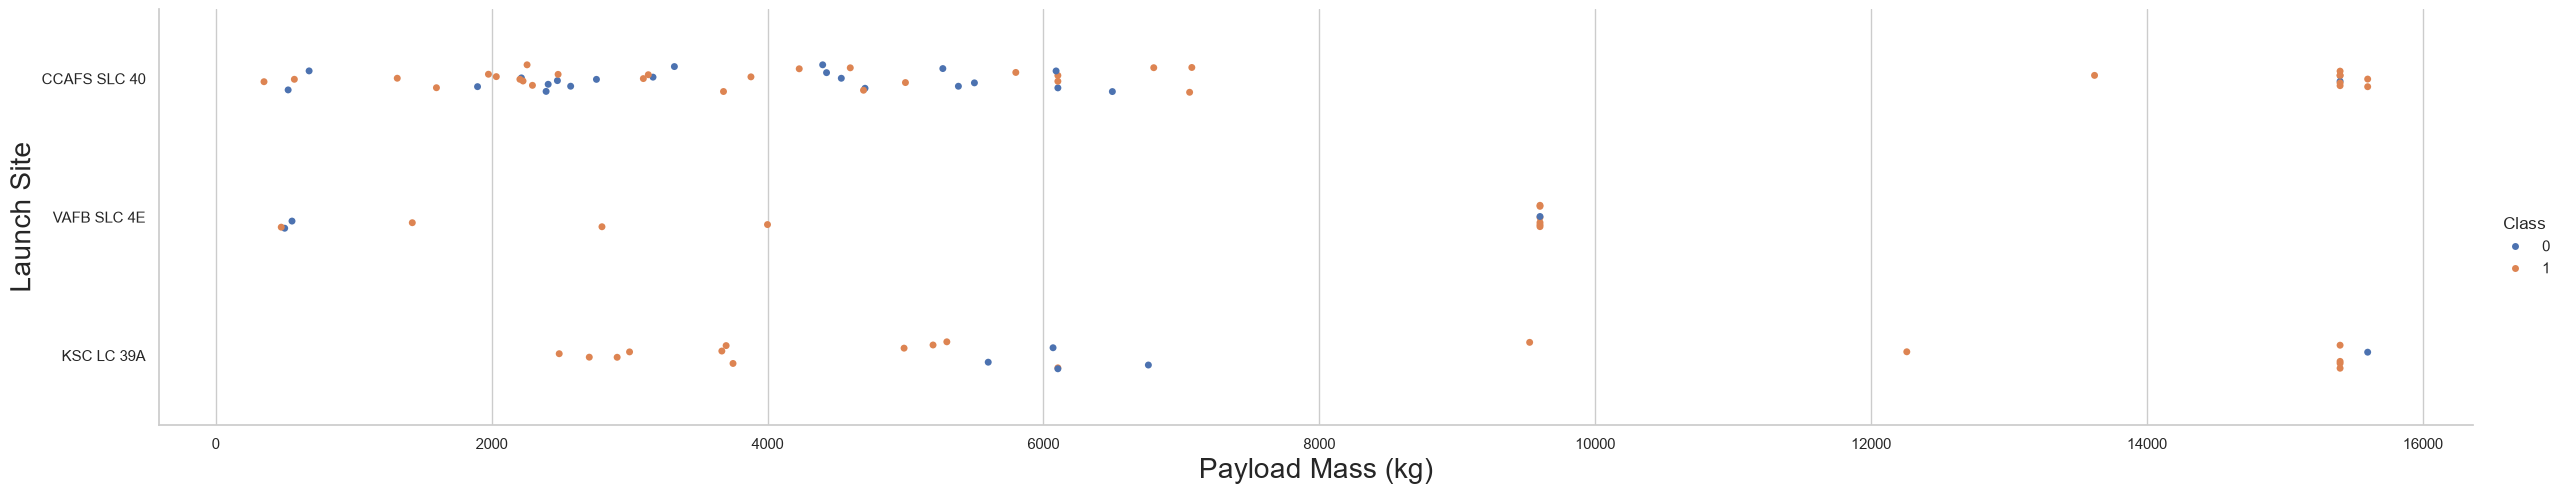

In [5]:
sns.catplot(y='LaunchSite', x='PayloadMass', hue='Class', data=df, aspect=5)
plt.xlabel('Payload Mass (kg)', fontsize=20); plt.ylabel('Launch Site', fontsize=20)
plt.show()

## Success rate by orbit type

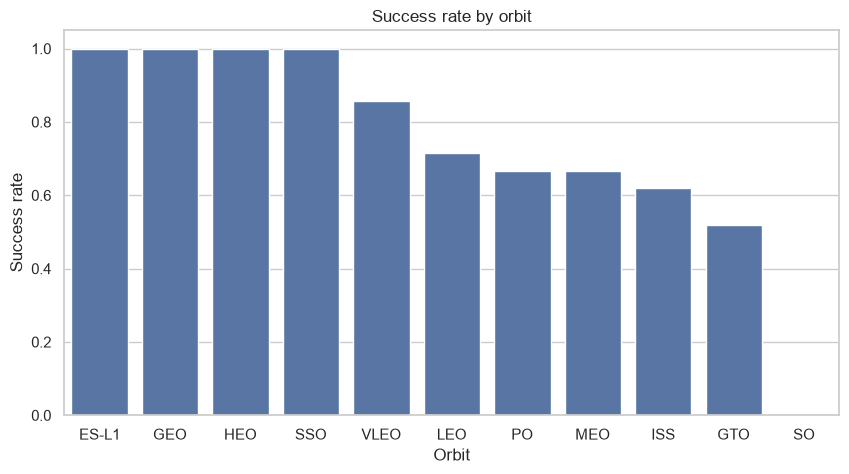

,Orbit,Class
0,ES-L1,1.000000
1,GEO,1.000000
3,HEO,1.000000
9,SSO,1.000000
10,VLEO,0.857143
5,LEO,0.714286
7,PO,0.666667
6,MEO,0.666667
4,ISS,0.619048
2,GTO,0.518519


In [6]:
orbit_rate = df.groupby('Orbit')['Class'].mean().reset_index().sort_values('Class', ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x='Orbit', y='Class', data=orbit_rate)
plt.ylabel('Success rate'); plt.title('Success rate by orbit')
plt.show()
orbit_rate

## Flight Number vs Orbit

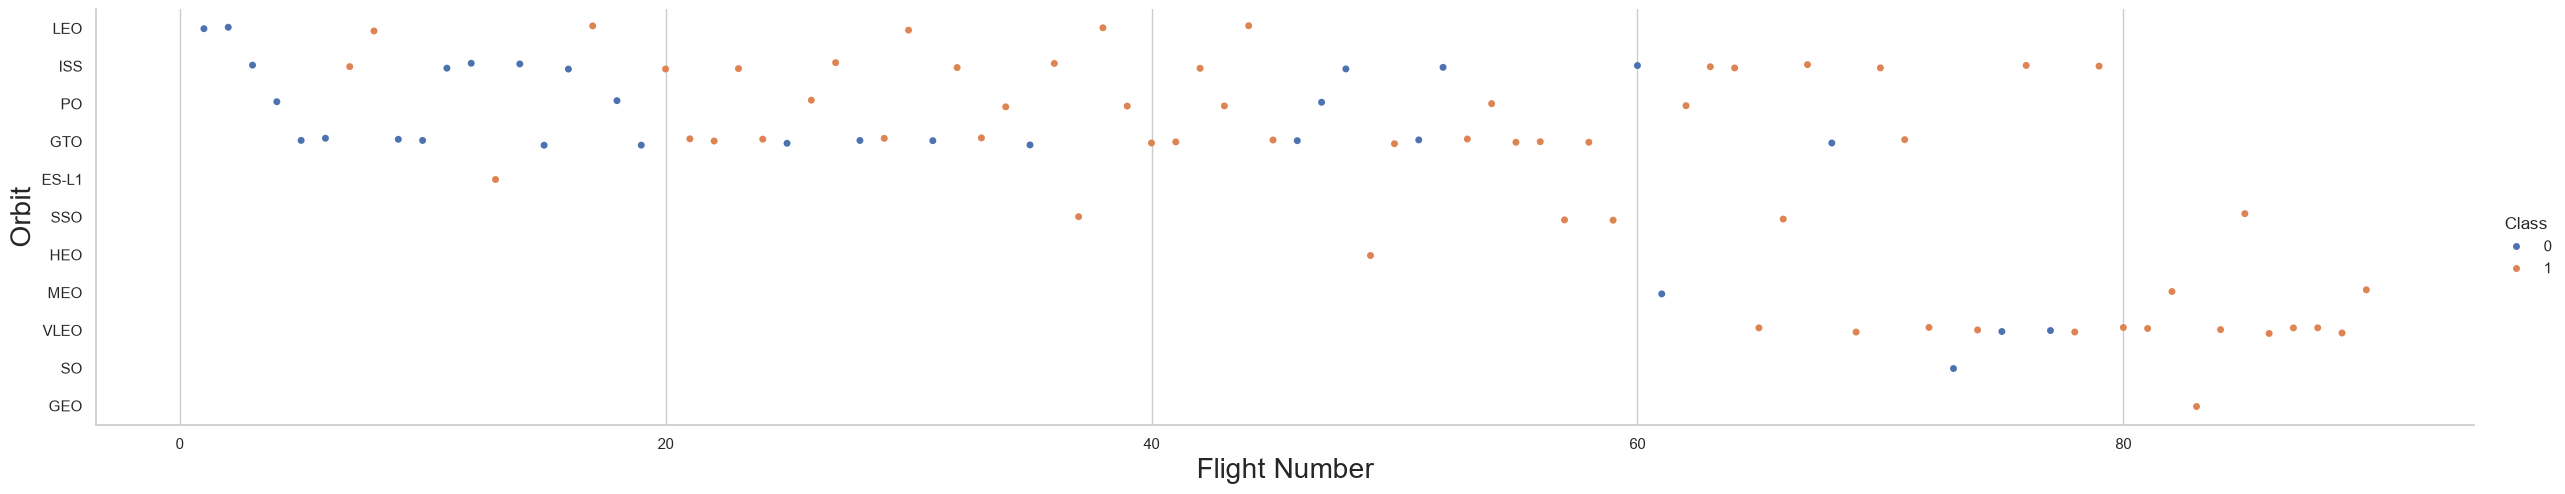

In [7]:
sns.catplot(y='Orbit', x='FlightNumber', hue='Class', data=df, aspect=5)
plt.xlabel('Flight Number', fontsize=20); plt.ylabel('Orbit', fontsize=20)
plt.show()

## Payload vs Orbit

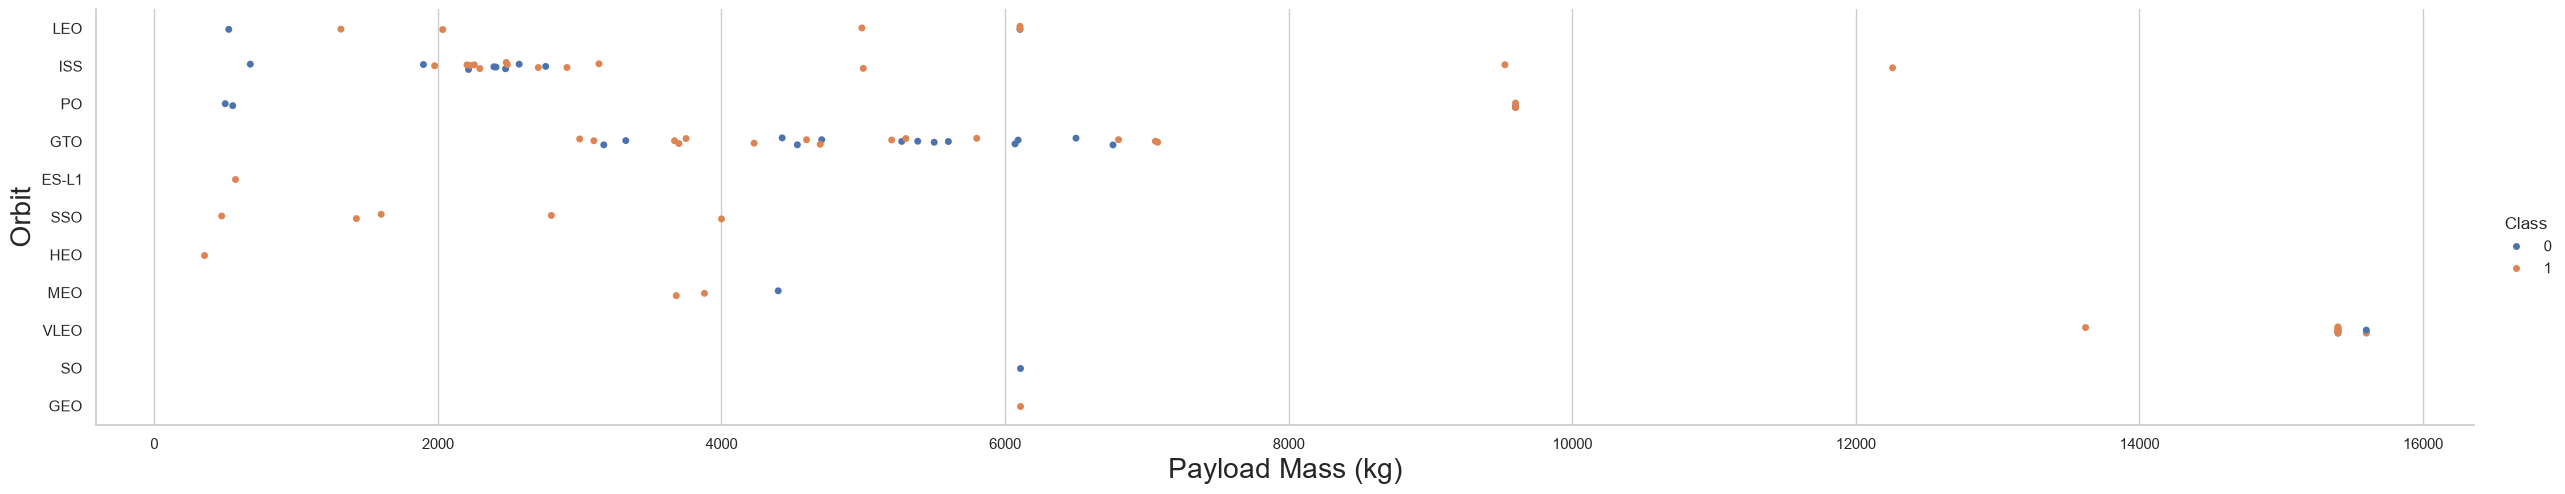

In [8]:
sns.catplot(y='Orbit', x='PayloadMass', hue='Class', data=df, aspect=5)
plt.xlabel('Payload Mass (kg)', fontsize=20); plt.ylabel('Orbit', fontsize=20)
plt.show()

## Yearly success trend

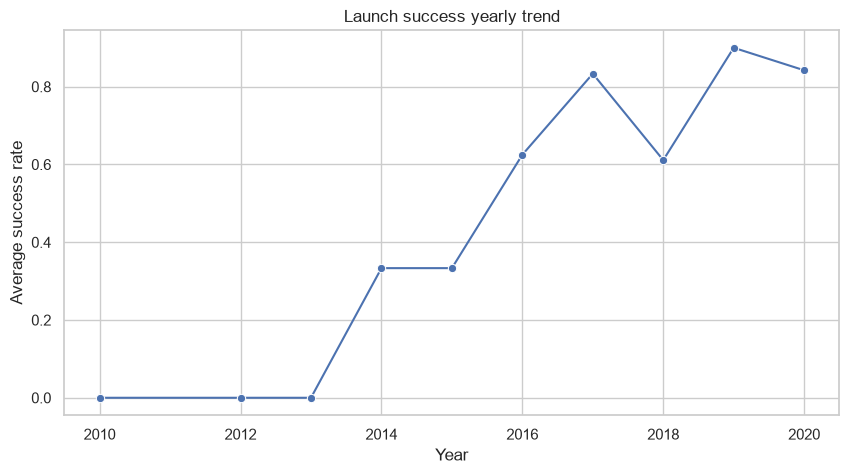

,Year,Class
0,2010,0.000000
1,2012,0.000000
2,2013,0.000000
3,2014,0.333333
4,2015,0.333333
5,2016,0.625000
6,2017,0.833333
7,2018,0.611111
8,2019,0.900000
9,2020,0.842105


In [9]:
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly = df.groupby('Year')['Class'].mean().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(x='Year', y='Class', data=yearly, marker='o')
plt.xlabel('Year'); plt.ylabel('Average success rate'); plt.title('Launch success yearly trend')
plt.show()
yearly

## Feature engineering

In [10]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins',
               'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot = features_one_hot.astype('float64')
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6104.959412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
features_one_hot.to_csv('dataset_part_3.csv', index=False)
features_one_hot.shape

(90, 80)